 #(Single-Layer Perceptron from Scratch



In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [29]:
df=pd.read_csv("Breast Cancer .csv")
print("data set loaded successfully")
df.head()

data set loaded successfully


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [30]:
df.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


In [31]:
df.shape

(569, 33)

In [32]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [34]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


## 2. Preprocessing

In [35]:
df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [36]:
print("duplicate rows:", df.duplicated().sum())

duplicate rows: 0


In [37]:
#The column `id` is only an identifier and `Unnamed: 32` is an empty column, so both are dropped.
df=df.drop(columns=['id','Unnamed: 32'])
df.shape

(569, 31)

The target column `diagnosis` has letters (M = Malignant, B = Benign).

In [38]:
df['diagnosis']=df['diagnosis'].map({'M':1,'B':0})
print(df['diagnosis'].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


In [39]:
y=df['diagnosis'].values
x=df.drop(columns=['diagnosis']).values
print("x shape:",x.shape)
print("y shape:",y.shape)

x shape: (569, 30)
y shape: (569,)


### Train-test split 

In [40]:
x_train,x_test,y_train,y_test=train_test_split(x,y, test_size=0.3, random_state=42)

In [41]:
print("training shape:", x_train.shape)
print("testing shape:", x_test.shape)

training shape: (398, 30)
testing shape: (171, 30)


### Feature scaling 


In [42]:
mean=x_train.mean(axis=0)
std=x_train.std(axis=0)

x_train=(x_train-mean)/std
x_test=(x_test-mean)/std
print("scaling done")

scaling done


## 3. Single-Layer Perceptron 

In [43]:
class Perceptron:

    def __init__(self, learning_rate=0.01, epochs=50):
        self.lr=learning_rate
        self.epochs=epochs
        self.weights=None
        self.bias=0
        self.errors=[]

    def net_input(self, x):
        return np.dot(x, self.weights)+self.bias

    def predict(self, x):
        return np.where(self.net_input(x)>=0, 1, 0)

    def fit(self, x, y):
        n_samples, n_features = x.shape
        self.weights=np.zeros(n_features)
        self.bias=0
        self.errors=[]

        for epoch in range(self.epochs):
            wrong=0
            for xi, target in zip(x, y):
                pred=self.predict(xi)
                update=self.lr*(target-pred)
                self.weights=self.weights+update*xi
                self.bias=self.bias+update
                if update!=0:
                    wrong+=1
            self.errors.append(wrong)
            print("Epoch", epoch+1, "- misclassified:", wrong)

## 4. Train the model

In [44]:
model=Perceptron(learning_rate=0.01, epochs=50)
model.fit(x_train, y_train)
print("model train succesfully")

Epoch 1 - misclassified: 31
Epoch 2 - misclassified: 16
Epoch 3 - misclassified: 13
Epoch 4 - misclassified: 15
Epoch 5 - misclassified: 15
Epoch 6 - misclassified: 11


Epoch 7 - misclassified: 11
Epoch 8 - misclassified: 15
Epoch 9 - misclassified: 19
Epoch 10 - misclassified: 9
Epoch 11 - misclassified: 9
Epoch 12 - misclassified: 6
Epoch 13 - misclassified: 12
Epoch 14 - misclassified: 8
Epoch 15 - misclassified: 7
Epoch 16 - misclassified: 11
Epoch 17 - misclassified: 2
Epoch 18 - misclassified: 12
Epoch 19 - misclassified: 14
Epoch 20 - misclassified: 12
Epoch 21 - misclassified: 9
Epoch 22 - misclassified: 12
Epoch 23 - misclassified: 8
Epoch 24 - misclassified: 10
Epoch 25 - misclassified: 9
Epoch 26 - misclassified: 12
Epoch 27 - misclassified: 7
Epoch 28 - misclassified: 10
Epoch 29 - misclassified: 14
Epoch 30 - misclassified: 10
Epoch 31 - misclassified: 9
Epoch 32 - misclassified: 8
Epoch 33 - misclassified: 11
Epoch 34 - misclassified: 12
Epoch 35 - misclassified: 7
Epoch 36 - misclassified: 10
Epoch 37 - misclassified: 12
Epoch 38 - misclassified: 8
Epoch 39 - misclassified: 8
Epoch 40 - misclassified: 7
Epoch 41 - misclassified: 10
Epoc

## 5. Predictions

In [45]:
y_pred_train=model.predict(x_train)
y_pred=model.predict(x_test)

## 6. Evaluation 

In [46]:
TP=np.sum((y_test==1)&(y_pred==1))
TN=np.sum((y_test==0)&(y_pred==0))
FP=np.sum((y_test==0)&(y_pred==1))
FN=np.sum((y_test==1)&(y_pred==0))

accuracy=(TP+TN)/(TP+TN+FP+FN)
precision=TP/(TP+FP)
recall=TP/(TP+FN)
f1=2*precision*recall/(precision+recall)

train_accuracy=np.mean(y_pred_train==y_train)

print("Confusion Matrix:")
print("TN:",TN," FP:",FP)
print("FN:",FN," TP:",TP)
print()
print("train accuracy:",round(train_accuracy,4))
print("test accuracy :",round(accuracy,4))
print("precision     :",round(precision,4))
print("recall        :",round(recall,4))
print("f1_score      :",round(f1,4))

Confusion Matrix:
TN: 105  FP: 3
FN: 3  TP: 60

train accuracy: 0.9824
test accuracy : 0.9649
precision     : 0.9524
recall        : 0.9524
f1_score      : 0.9524


In [47]:
results=pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})
results['Correct']=(results['Actual']==results['Predicted'])
results.head(10)

,Actual,Predicted,Correct
0,0,0,True
1,1,1,True
2,1,1,True
3,0,0,True
4,0,0,True
5,1,1,True
6,1,1,True
7,1,1,True
8,0,1,False
9,0,0,True


## 7. Visualizations

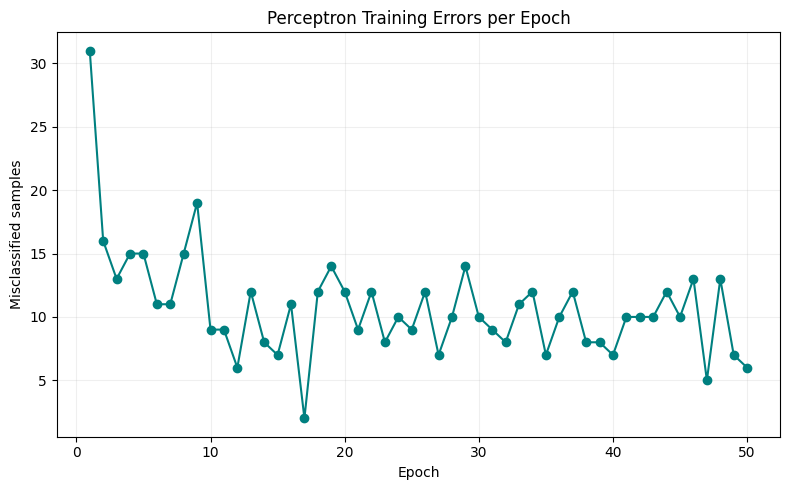

In [48]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(model.errors)+1), model.errors, marker='o', color='teal')
plt.xlabel("Epoch")
plt.ylabel("Misclassified samples")
plt.title("Perceptron Training Errors per Epoch")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

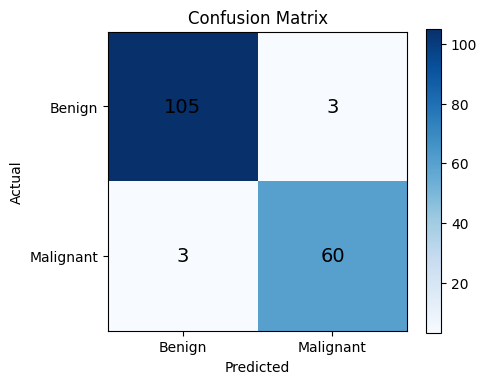

In [49]:
cm=np.array([[TN, FP],
             [FN, TP]])

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks([0, 1], ['Benign', 'Malignant'])
plt.yticks([0, 1], ['Benign', 'Malignant'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=14)

plt.tight_layout()
plt.show()

## 8. Conclusion
- A Single-Layer Perceptron was built from scratch using only NumPy (no prebuilt ML model).
- The dataset was cleaned, the labels were encoded, the features were standardized, and the data was split 70/30.
- The model learned by the perceptron rule and the errors per epoch went down during training.
- The final performance on the test data is shown above using accuracy, precision, recall, F1-score and the confusion matrix.

In [50]:
feature_names = np.array(list(df.drop(columns=['diagnosis']).columns), dtype='U40')

np.savez("perceptron_model.npz",
         weights=model.weights,
         bias=model.bias,
         mean=mean,
         std=std,
         features=feature_names)
print("model saved")

model saved
